In [1]:
import numpy as np
import cv2, PIL
from cv2 import aruco
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
#source: https://mecaruco2.readthedocs.io/en/latest/notebooks_rst/Aruco/aruco_basics.html

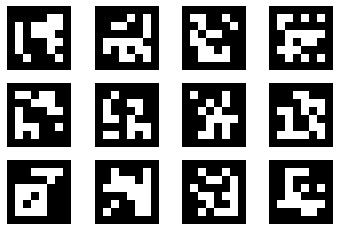

In [2]:
aruco_dict = aruco.Dictionary_get(aruco.DICT_6X6_250)

fig = plt.figure()
nx = 4
ny = 3
for i in range(1, nx*ny+1):
    ax = fig.add_subplot(ny,nx, i)
    img = aruco.drawMarker(aruco_dict,i, 700)
    plt.imshow(img, cmap = mpl.cm.gray, interpolation = "nearest")
    ax.axis("off")

plt.savefig("markers.pdf")
plt.show()

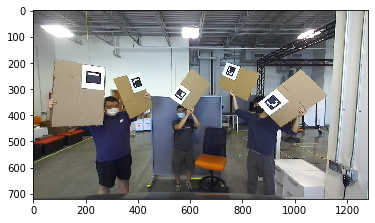

In [3]:
frame = cv2.imread("static_aruco.png")
frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

plt.figure()
plt.imshow(frame)
plt.show()

In [5]:
%%time
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
aruco_dict = aruco.Dictionary_get(aruco.DICT_ARUCO_ORIGINAL)
parameters =  aruco.DetectorParameters_create()
corners, ids, rejectedImgPoints = aruco.detectMarkers(gray, aruco_dict, parameters=parameters)
print(corners)
frame_markers = aruco.drawDetectedMarkers(frame.copy(), corners, ids)
plt.imshow(frame_markers)

[array([[[883., 350.],
        [918., 323.],
        [948., 354.],
        [912., 380.]]], dtype=float32), array([[[541., 325.],
        [559., 299.],
        [584., 317.],
        [567., 343.]]], dtype=float32), array([[[404., 254.],
        [417., 287.],
        [388., 297.],
        [375., 263.]]], dtype=float32), array([[[748., 212.],
        [774., 221.],
        [761., 253.],
        [736., 243.]]], dtype=float32), array([[[259., 239.],
        [257., 281.],
        [203., 276.],
        [204., 231.]]], dtype=float32)]


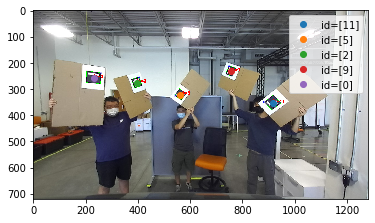

In [ ]:
plt.figure()
plt.imshow(frame_markers)
for i in range(len(ids)):
    c = corners[i][0]
    plt.plot([c[:, 0].mean()], [c[:, 1].mean()], "o", label = "id={0}".format(ids[i]))
plt.legend()
plt.savefig("aruco_detected.png")
plt.show()
